In [37]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("CSV files here:", list(Path(".").glob("**/C1_*_stats.csv"))[:10])

Current directory: /home/mignoe/Documents/git/Roteiro2-VirtualBox/results
CSV files here: [PosixPath('C1/C1_cpu_100users_stats.csv'), PosixPath('C1/C1_cpu_200users_stats.csv'), PosixPath('C1/C1_cpu_300users_stats.csv'), PosixPath('C1/C1_cpu_400users_stats.csv'), PosixPath('C1/C1_memory_100users_stats.csv'), PosixPath('C1/C1_memory_200users_stats.csv'), PosixPath('C1/C1_memory_300users_stats.csv'), PosixPath('C1/C1_memory_400users_stats.csv'), PosixPath('C1/C1_io_100users_stats.csv'), PosixPath('C1/C1_io_200users_stats.csv')]


In [ ]:

from pathlib import Path
import pandas as pd

SCENARIOS = ["C1", "C2", "C3", "C4"]

SCENARIO = "C4"
FILES_PATH = Path(f"./{SCENARIO}")

data = []

for file in sorted(FILES_PATH.glob(f"{SCENARIO}_*_stats.csv")):
    df = pd.read_csv(file)
    aggregated = df[df["Name"] == "Aggregated"]

    if aggregated.empty:
        continue

    row = aggregated.iloc[-1]
    parts = file.stem.split("_")

    data.append({
        "application": parts[1],
        "users": int(parts[2].replace("users", "")),
        "requests": row["Request Count"],
        "requests_per_second": row["Requests/s"],
        "avg_response_time_ms": row["Average Response Time"],
        "failures": row["Failure Count"],
    })

results = pd.DataFrame(data)

if not results.empty:
    results = results.sort_values(
        ["application", "users"]
    ).reset_index(drop=True)
    display(results)
else:
    print(f"No results found in {FILES_PATH.resolve()}")


,application,users,requests,requests_per_second,avg_response_time_ms,failures
0,cpu,100,919,65.590784,115.565626,0
1,cpu,200,1806,129.002432,119.462171,0
2,cpu,300,2885,205.928377,26.672392,0
3,cpu,400,3846,274.580900,20.134402,0
4,memory,100,959,68.623234,22.471937,0
5,memory,200,1948,139.203132,11.092398,0
6,memory,300,2919,208.360259,14.143917,0
7,memory,400,3818,272.624170,38.181404,0


In [41]:
from pathlib import Path
import pandas as pd

SCENARIOS = ["C1", "C2", "C3", "C4"]

resource_results = {}

for scenario in SCENARIOS:
    files_path = Path(f"./{scenario}")
    data = []

    for file in sorted(files_path.glob(f"{scenario}_*_vmstat.txt")):
        parts = file.stem.split("_")
        application = parts[1]
        users = int(parts[2].replace("users", ""))

        lines = file.read_text().splitlines()

        header_idx = next(
            (i for i, line in enumerate(lines)
             if "swpd" in line.split() and "free" in line.split()),
            None
        )
        if header_idx is None:
            continue

        columns = lines[header_idx].split()
        rows = []

        for line in lines[header_idx + 1:]:
            values = line.split()
            if len(values) < len(columns):
                continue
            try:
                rows.append([float(v) for v in values[:len(columns)]])
            except ValueError:
                continue

        if len(rows) < 2:
            continue

        df = pd.DataFrame(rows, columns=columns).iloc[1:]

        data.append({
            "application": application,
            "users": users,
            "cpu_util_pct": 100 - df["id"].mean(),
            "free_memory_mb": df["free"].mean() / 1024,
        })

    resource_results[scenario] = pd.DataFrame(data)

# Example: inspect one scenario
display(resource_results["C4"])

""


In [42]:
display(resource_results["C4"])

""


In [43]:
resource_results

{'C1': Empty DataFrame
 Columns: []
 Index: [],
 'C2': Empty DataFrame
 Columns: []
 Index: [],
 'C3': Empty DataFrame
 Columns: []
 Index: [],
 'C4': Empty DataFrame
 Columns: []
 Index: []}

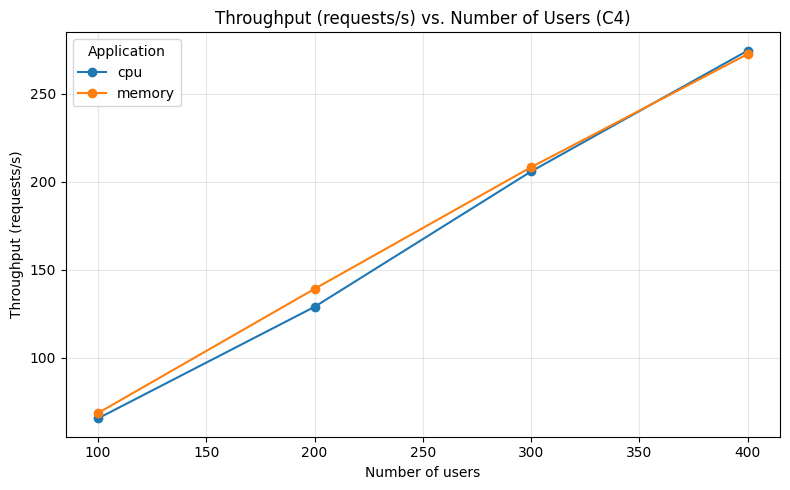

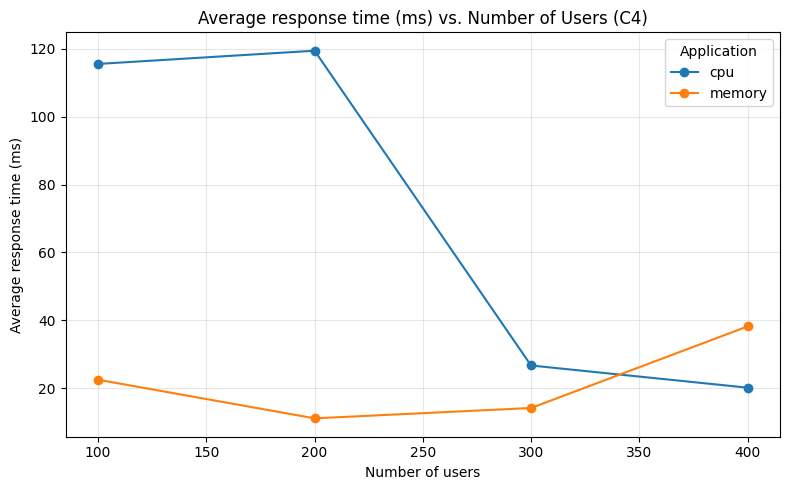

In [40]:
import matplotlib.pyplot as plt

metrics = [
    ("requests_per_second", "Throughput (requests/s)"),
    ("avg_response_time_ms", "Average response time (ms)"),
]

for metric, ylabel in metrics:
    plt.figure(figsize=(8, 5))

    for app, group in results.groupby("application"):
        if app == "io":
            continue

        plt.plot(
            group["users"],
            group[metric],
            marker="o",
            label=app
        )

    plt.xlabel("Number of users")
    plt.ylabel(ylabel)
    plt.title(f"{ylabel} vs. Number of Users ({SCENARIO})")
    plt.legend(title="Application")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()